In [46]:
import torch  
import torch.nn as nn  
import torch.optim as optim
import torch.nn.functional as F 
from data_setup import RotatedMNIST, create_dataloaders
from vae_setup import VAE
from model import MultiTaskDNN
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

In [7]:
# Training configs
training_data_cfg = {
    'dataset_path': './DNN_Data',
    'batch_size': 32,
    'num_workers': 0,  # Set to 0 to avoid multiprocessing issues during plotting
    'max_digit': 9,
    'max_rotation_degrees': 360
}

training_model_cfg = {
    'input_shape': 784,
    'shared_layers': 3,
    'task_layers': 3,
    'shared_nodes': 64,
    'task_nodes': 32,
    'digit_out': 10,
    'parity_out': 2,
    'rotation_out': 1
}

train_cfg = {
    'activation': 'relu'
}

# Trainig/test loaders
train_loader, test_loader = create_dataloaders(training_data_cfg)

# Load model from filepath
def load_DNN_model(filename):
    new_model = MultiTaskDNN(training_model_cfg, train_cfg)
    state_dict = torch.load(filename, map_location="cpu", weights_only=True)
    new_model.load_state_dict(state_dict, strict=True)
    return new_model

BASE_MODEL_FILEPATH = "wide-models/wide-1000-epoch-model.pkl"
base_model = load_DNN_model(BASE_MODEL_FILEPATH)

In [51]:
# VAE loss function, where total loss = reconstruction loss + KL divergence
def vae_loss(recon, X, mu, logvar, likelihood):
    # Reconstruction: negative log-likelihood, averaged over batch
    if likelihood == "gaussian":
        # Gaussian NLL ∝ MSE
        recon_loss = F.mse_loss(recon, X, reduction="mean")
    elif likelihood == "poisson":
        # Poisson NLL = mean over batch of sum over units (λ - k·log λ)
        log_factorial = torch.lgamma(X + 1)
        recon_loss = (recon - X * torch.log(recon + 1e-8) + log_factorial).sum(dim=1).mean()
        recon_loss = recon_loss / (X.mean() + 1e-8)
    # KL averaged over batch
    kl_loss = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
    return recon_loss + kl_loss, recon_loss, kl_loss

# Use GPU if available  
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# VAE training function
def train_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2):
    assert likelihood in ("gaussian", "poisson")
	
    # Initialize batches and model
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)
    
    input_dim = X.shape[1]
    vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim, likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=1e-3)
    
    # Track losses 
    train_losses = []
    recon_losses = []
    kl_losses = []
    
    # Training loop
    vae_model.train()
    for epoch in range(n_epochs+1):
        total_train_loss = 0
        total_recon_loss = 0
        total_kl_loss = 0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = vae_model(xb)
            
            train_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)
            total_train_loss += train_loss.item()
            total_recon_loss += recon_loss.item()
            total_kl_loss += kl_loss.item()
            
            train_loss.backward()
            optimizer.step()

        train_losses.append(total_train_loss)
        recon_losses.append(total_recon_loss)
        kl_losses.append(total_kl_loss)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: loss={total_train_loss:.3f} recon={total_recon_loss:.3f} kl={total_kl_loss:.3f}")

	# Return model and training logs
    logs = {"training_losses": train_losses, "recon_losses": recon_losses, "kl_losses": kl_losses}
    return vae_model, logs

In [49]:
# Collect labels/activations
digit_labels = []
rot_labels = []
first_digit_layer_X = []
last_digit_layer_X = []

base_model.eval()
with torch.no_grad():
    for images, digits, angle_rad, angle_deg in test_loader:
        # Make predictions
        digit_logits, parity_logits, rot_preds, acts = base_model(images)

        # Record digit and rotation labels
        digit_labels.extend(list(digits))
        rot_labels.extend(list(angle_rad))

        # Record first and last digit layer activations
        first_digit_layer_X.append(acts["Digit_Layer_0"].detach().cpu())
        last_digit_layer_X.append(acts["Digit_Layer_2"].detach().cpu())

# Stack into single tensors: [N, 32]
first_digit_layer_X = torch.cat(first_digit_layer_X, dim=0)
last_digit_layer_X  = torch.cat(last_digit_layer_X,  dim=0)

In [150]:
# Set training parameters 
n_epochs = 100
batch_size = 64
learning_rate = 1e-3
likelihood = "gaussian"

# Train VAE model
first_layer_vae_model, logs = train_VAE(first_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2)

epoch 0: loss=65.771 recon=65.176 kl=0.595
epoch 10: loss=63.693 recon=63.633 kl=0.060
epoch 20: loss=63.582 recon=63.562 kl=0.020
epoch 30: loss=63.343 recon=63.337 kl=0.007
epoch 40: loss=63.231 recon=63.228 kl=0.003
epoch 50: loss=63.159 recon=63.158 kl=0.001
epoch 60: loss=63.145 recon=63.144 kl=0.001
epoch 70: loss=63.200 recon=63.199 kl=0.001
epoch 80: loss=63.088 recon=63.087 kl=0.001
epoch 90: loss=63.122 recon=63.121 kl=0.001
epoch 100: loss=63.115 recon=63.115 kl=0.000


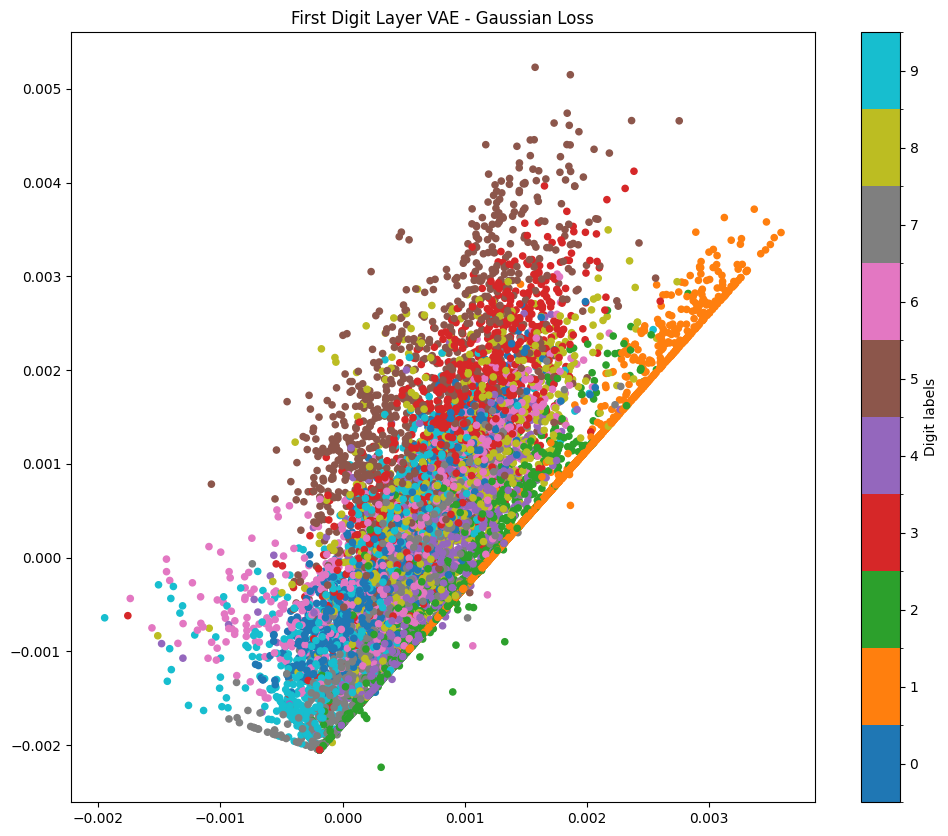

In [151]:
first_layer_vae_model.eval()
with torch.no_grad():
    mu_all, _ = first_layer_vae_model.encoder(first_digit_layer_X) # encode all available data
    Z = mu_all.cpu().numpy()
    
cmap = plt.get_cmap("tab10")   # 10 distinct colors
norm = mcolors.BoundaryNorm(boundaries=np.arange(-1/2, 10), ncolors=10)

sc = plt.scatter(Z[:, 0], Z[:, 1], c=digit_labels, cmap=cmap, norm=norm, s=20)
cbar = plt.colorbar(sc, ticks=range(10))
cbar.set_label("Digit labels")
plt.title("First Digit Layer VAE - Gaussian Loss")

fig = plt.gcf()
fig.set_size_inches(12, 10)

plt.show()

In [152]:
def graph_VAE_latent_space(vae_model, X, label, transform=None):
# Do forward pass on VAE encoding of the digit-layer activations
    vae_model.eval()
    with torch.no_grad():
        mu_all, sd_all = vae_model.encoder(X)  # [N, 2], [N, 2]
        Z = mu_all.cpu().numpy()

     # Apply fitted Procrustes transform (if any) before plotting
    if transform is not None:
        Z = apply_procrustes_similarity(Z, transform)

    # Calculate per-digit latent variance for both dimensions 
    var_np = sd_all ** 2 
    digits_np = np.asarray([int(d) for d in digit_labels])
    
    unique_digits = range(10)
    # Find avg variance per digit / latent dimension
    avg_var_per_digit = np.stack([var_np[digits_np == d].mean(axis=0) for d in unique_digits], axis=0)
    
    # Make figure: VAE scatter (left), per-digit latent variance (right)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left: VAE latent space scatter plot
    cmap = plt.get_cmap("tab10")
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-1/2, 10), ncolors=10)
    sc = ax1.scatter(Z[:, 0], Z[:, 1], c=digit_labels, cmap=cmap, norm=norm, s=20)

    # Color in digits 
    cbar = fig.colorbar(sc, ax=ax1, ticks=unique_digits)
    cbar.set_label("Digit labels")
    ax1.set_title(f"{label} VAE Latent Space")
    ax1.set_xlabel("z[0]")
    ax1.set_ylabel("z[1]")
    
    # Right: grouped bars, one group per digit, one bar per latent dim
    x = np.arange(len(unique_digits))
    width = 0.4
    ax2.bar(x - width/2, avg_var_per_digit[:, 0], width, label="z[0] Var", color="steelblue")
    ax2.bar(x + width/2, avg_var_per_digit[:, 1], width, label="z[1] Var", color="darkorange")
    ax2.set_xticks(x)
    ax2.set_xticklabels(unique_digits)
    ax2.set_xlabel("digit")
    ax2.set_ylabel("mean latent variance")
    ax2.set_title(f"{label} Avg. Latent Variance per Digit")
    ax2.legend()
    ax2.grid(axis="y", alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [101]:
def procrustes_latent_penalty(mu_student, mu_teacher, center=True, scale=True):
    """
    Procrustes distance between two sets of 2D latent codes.

    Takes in both mu predictions from student and teacher as input.
    Returns Procrustes distance, i.e. squared residual norm.
    """
    # Center
    if center:
        s = mu_student - mu_student.mean(dim=0, keepdim=True)
        t = mu_teacher - mu_teacher.mean(dim=0, keepdim=True)
    else:
        s, t = mu_student, mu_teacher

    # Normalize scale between both 
    if scale:
        s = s / (s.norm() + 1e-8)
        t = t / (t.norm() + 1e-8)

    # Optimal orthogonal transform Q minimizing ||s Q - t||_F  (solve on teacher side)
    # M = s^T t ; SVD M = U S V^T ; Q = U V^T
    M = s.t() @ t
    U, _, Vt = torch.linalg.svd(M)
    Q = U @ Vt

    # Residual after alignment
    residual = s @ Q - t
    # Normalize so the penalty is scale-free and comparable across batches
    denom = t.norm() + 1e-8
    return (residual.norm() / denom) ** 2   # squared relative Procrustes distance

def train_VAE_with_procrustes(X, likelihood, batch_size, n_epochs, learning_rate,
                              teacher_model, proc_lambda=0.1,
                              latent_dim=2, procrustes_scale=True):
    assert likelihood in ("gaussian", "poisson")
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)

    input_dim = X.shape[1]
    vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim,
                    likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

    teacher_model.eval()
    for p in teacher_model.parameters():
        p.requires_grad_(False)          # freeze teacher

    train_losses, recon_losses, kl_losses, proc_losses = [], [], [], []

    vae_model.train()
    for epoch in range(n_epochs + 1):
        tot = rec = kl = proc = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = vae_model(xb)

            # Calculate base VAE loss
            base_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)

            # Find teacher latents for the same batch
            with torch.no_grad():
                mu_teacher, _ = teacher_model.encoder(xb)

            # Calculate Procrustes penalty
            proc_loss = procrustes_latent_penalty(mu, mu_teacher, scale=procrustes_scale)
            
            # Combine together for total loss, scaling proc_loss by proc_lambda
            proc_loss *= proc_lambda
            total = base_loss + proc_loss
            total.backward()
            optimizer.step()

            tot  += total.item()
            rec  += recon_loss.item()
            kl   += kl_loss.item()
            proc += proc_loss.item()

        train_losses.append(tot); recon_losses.append(rec)
        kl_losses.append(kl);     proc_losses.append(proc)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: total={tot:.3f} recon={rec:.3f} "
                  f"kl={kl:.3f} proc={proc:.3f}")

    logs = {"training_losses": train_losses, "recon_losses": recon_losses,
            "kl_losses": kl_losses, "procrustes_losses": proc_losses}
    return vae_model, logs

In [155]:
# Set training parameters 
n_epochs = 100
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"
teacher_model = first_layer_vae_model
proc_lambda = 10000

# Train VAE model
last_layer_vae_model, logs = train_VAE_with_procrustes(last_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate,
                                       teacher_model, proc_lambda=proc_lambda, latent_dim=2)

epoch 0: total=414582.705 recon=172.444 kl=39.511 proc=414370.750
epoch 10: total=50542.309 recon=167.653 kl=28.724 proc=50345.932
epoch 20: total=33944.254 recon=166.433 kl=35.630 proc=33742.190
epoch 30: total=25593.514 recon=165.747 kl=40.814 proc=25386.953
epoch 40: total=16804.862 recon=165.424 kl=40.646 proc=16598.792
epoch 50: total=12763.224 recon=165.121 kl=46.301 proc=12551.802
epoch 60: total=11929.033 recon=164.369 kl=52.518 proc=11712.146
epoch 70: total=10247.177 recon=163.704 kl=59.658 proc=10023.815
epoch 80: total=9884.193 recon=163.114 kl=67.203 proc=9653.876
epoch 90: total=8556.168 recon=162.531 kl=74.092 proc=8319.545
epoch 100: total=6970.743 recon=162.272 kl=79.709 proc=6728.762


In [141]:
def fit_procrustes_similarity(Z_src, Z_ref, center=True, scale=True):
    """
    Fit transform (s, R, t) mapping Z_src -> Z_ref in the least-squares sense:
        Z_ref ≈ s * (Z_src - mu_src) @ R + mu_ref
    Z_*: [N, D] numpy arrays, SAME row correspondence.
    Returns dict with 'mu_src', 'mu_ref', 'R', 's'.
    """
    Z_src = np.asarray(Z_src, dtype=np.float64)
    Z_ref = np.asarray(Z_ref, dtype=np.float64)
    assert Z_src.shape == Z_ref.shape

    mu_src = Z_src.mean(axis=0) if center else np.zeros(Z_src.shape[1])
    mu_ref = Z_ref.mean(axis=0) if center else np.zeros(Z_ref.shape[1])
    S = Z_src - mu_src
    T = Z_ref - mu_ref

    # Orthogonal Procrustes: minimize ||S R - T||_F  s.t. R^T R = I
    M = S.T @ T
    U, _, Vt = np.linalg.svd(M)
    R = U @ Vt                       # [D, D], orthogonal (may be a reflection)

    # Optional isotropic scale (similarity Procrustes)
    if scale:
        # optimal scalar s = trace(S^T T R^T ... ) / ||S||_F^2
        denom = np.sum(S * S)
        num = np.sum((S @ R) * T)
        s = (num / denom) if denom > 0 else 1.0
    else:
        s = 1.0

    return {"mu_src": mu_src, "mu_ref": mu_ref, "R": R, "s": s}


def apply_procrustes_similarity(Z, transform):
    return transform["s"] * (Z - transform["mu_src"]) @ transform["R"] + transform["mu_ref"]

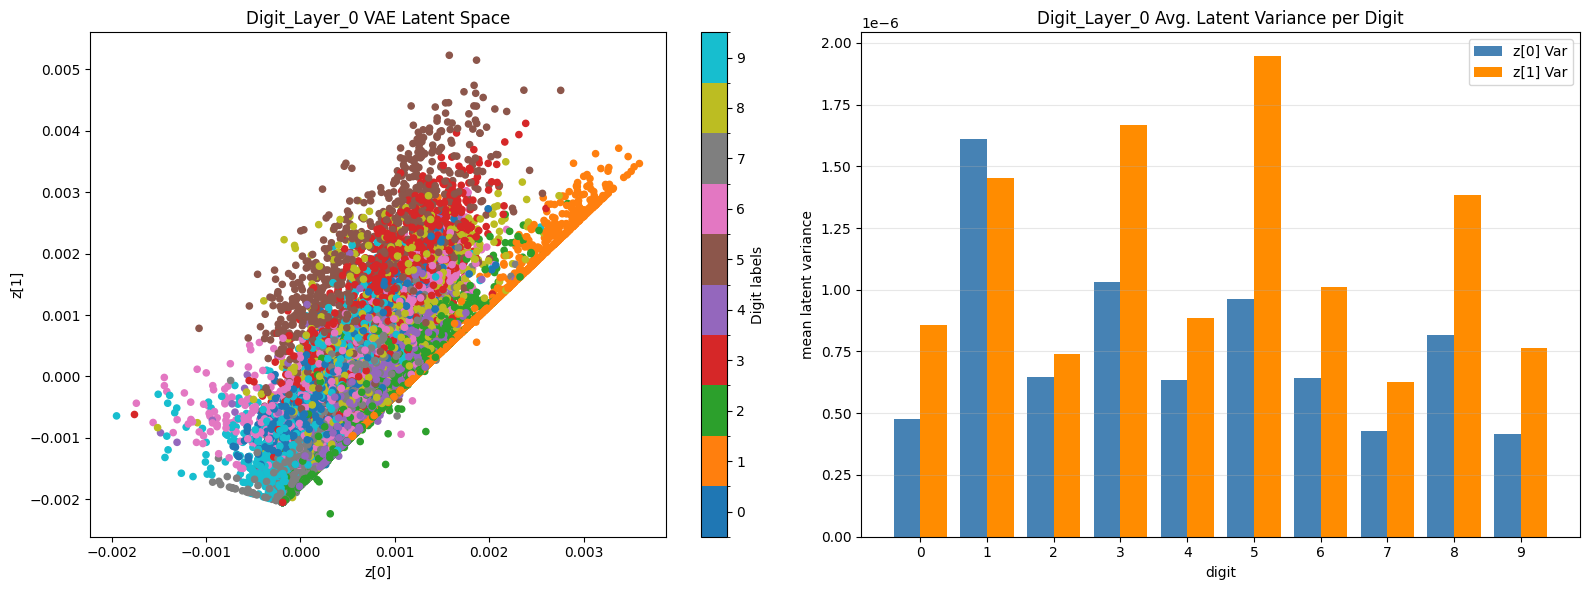

In [153]:
graph_VAE_latent_space(first_layer_vae_model, first_digit_layer_X, "Digit_Layer_0")

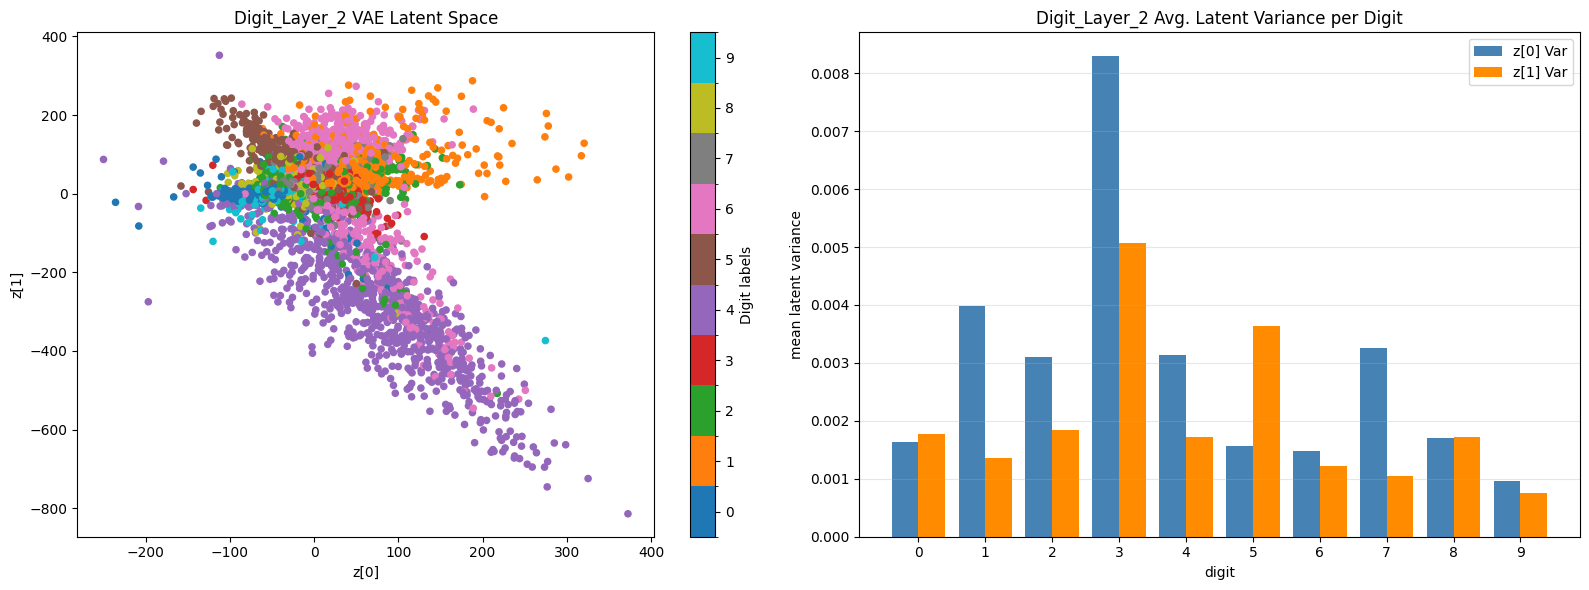

In [156]:
# 1) Get unaligned codes for both models (fit on these)
def _mu(vae, X):
    vae.eval()
    with torch.no_grad():
        mu, _ = vae.encoder(X)
    return mu.cpu().numpy()

Z_first = _mu(first_layer_vae_model, first_digit_layer_X)
Z_last  = _mu(last_layer_vae_model,  last_digit_layer_X)

# 2) Fit last -> first (anchor = first)
tf_last_to_first = fit_procrustes_similarity(Z_first, Z_last, center=True, scale=True)

graph_VAE_latent_space(last_layer_vae_model, last_digit_layer_X, "Digit_Layer_2", transform=tf_last_to_first)

In [182]:
def MSE_latent_penalty(mu_student, mu_teacher, normalize=True, per_dim=False):
    """
    MSE between student and teacher latent means, on the SAME examples.

    Args:
        mu_student: [B, D] student mu (differentiable)
        mu_teacher: [B, D] teacher mu (same row correspondence)
        normalize:  if True, divide by teacher variance so the term is scale-free
        per_dim:    if True, return per-dimension MSE [D] instead of a scalar

    Returns:
        scalar (or [D]) tensor
    """
    if per_dim:
        mse = (mu_student - mu_teacher).pow(2).mean(dim=0)   # [D]
        return mse / (mu_teacher.var(dim=0, unbiased=False) + 1e-8) if normalize else se
    mean_mse_across_dims = (mu_student - mu_teacher).pow(2).mean()
    if normalize:
        mean_mse_across_dims = mean_mse_across_dims / (mu_teacher.var(unbiased=False) + 1e-8)
    return mean_mse_across_dims

def train_VAE_with_MSE(X, likelihood, batch_size, n_epochs, learning_rate,
                       teacher_model, mse_lambda=0.1, latent_dim=2):
    assert likelihood in ("gaussian", "poisson")
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)

    input_dim = X.shape[1]
    vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim,
                    likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

    # Initialize log records
    train_losses = recon_losses = kl_losses = mse_losses = []
    vae_model.train()
    for epoch in range(n_epochs + 1):
        # Reset cumulative loss vars
        tot = rec = kl = mse = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = vae_model(xb)

            # Calculate base VAE loss
            base_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)

            # Find teacher latents for the same batch
            with torch.no_grad():
                mu_teacher, _ = teacher_model.encoder(xb)

            # Calculate MSE penalty
            mse_loss = MSE_latent_penalty(mu, mu_teacher)
            
            # Combine together for total loss, scaling mse_loss by mse_lambda
            mse_loss *= mse_lambda
            total = base_loss + mse_loss
            total.backward()
            optimizer.step()

            tot  += total.item()
            rec  += recon_loss.item()
            kl   += kl_loss.item()
            mse  += mse_loss.item()

        train_losses.append(tot); recon_losses.append(rec)
        kl_losses.append(kl); mse_losses.append(mse)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: total={tot:.3f} recon={rec:.3f} "
                  f"kl={kl:.3f} mse={mse:.3f}")

    logs = {"training_losses": train_losses, "recon_losses": recon_losses,
            "kl_losses": kl_losses, "mse_losses": mse_losses}
    return vae_model, logs

In [185]:
# Set training parameters 
n_epochs = 256
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"
teacher_model = first_layer_vae_model
mse_lambda = 100

# Train VAE model
last_layer_vae_model, logs = train_VAE_with_MSE(last_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate,
                                       teacher_model, mse_lambda=mse_lambda, latent_dim=2)

epoch 0: total=5283399.869 recon=177.981 kl=1.742 mse=5283220.122
epoch 10: total=207732.841 recon=172.086 kl=0.099 mse=207560.656
epoch 20: total=41111.588 recon=171.617 kl=0.048 mse=40939.923
epoch 30: total=16367.437 recon=171.492 kl=0.024 mse=16195.920
epoch 40: total=10849.252 recon=171.336 kl=0.016 mse=10677.900
epoch 50: total=4153.592 recon=171.251 kl=0.008 mse=3982.333
epoch 60: total=2758.211 recon=171.194 kl=0.005 mse=2587.012
epoch 70: total=1251.573 recon=170.983 kl=0.006 mse=1080.584
epoch 80: total=771.524 recon=171.035 kl=0.004 mse=600.484
epoch 90: total=842.301 recon=171.026 kl=0.003 mse=671.271
epoch 100: total=693.180 recon=171.163 kl=0.003 mse=522.014
epoch 110: total=701.898 recon=170.976 kl=0.003 mse=530.919
epoch 120: total=586.029 recon=170.808 kl=0.003 mse=415.217
epoch 130: total=640.349 recon=171.108 kl=0.003 mse=469.238
epoch 140: total=670.135 recon=170.972 kl=0.003 mse=499.159
epoch 150: total=578.355 recon=170.964 kl=0.003 mse=407.388
epoch 160: total=57

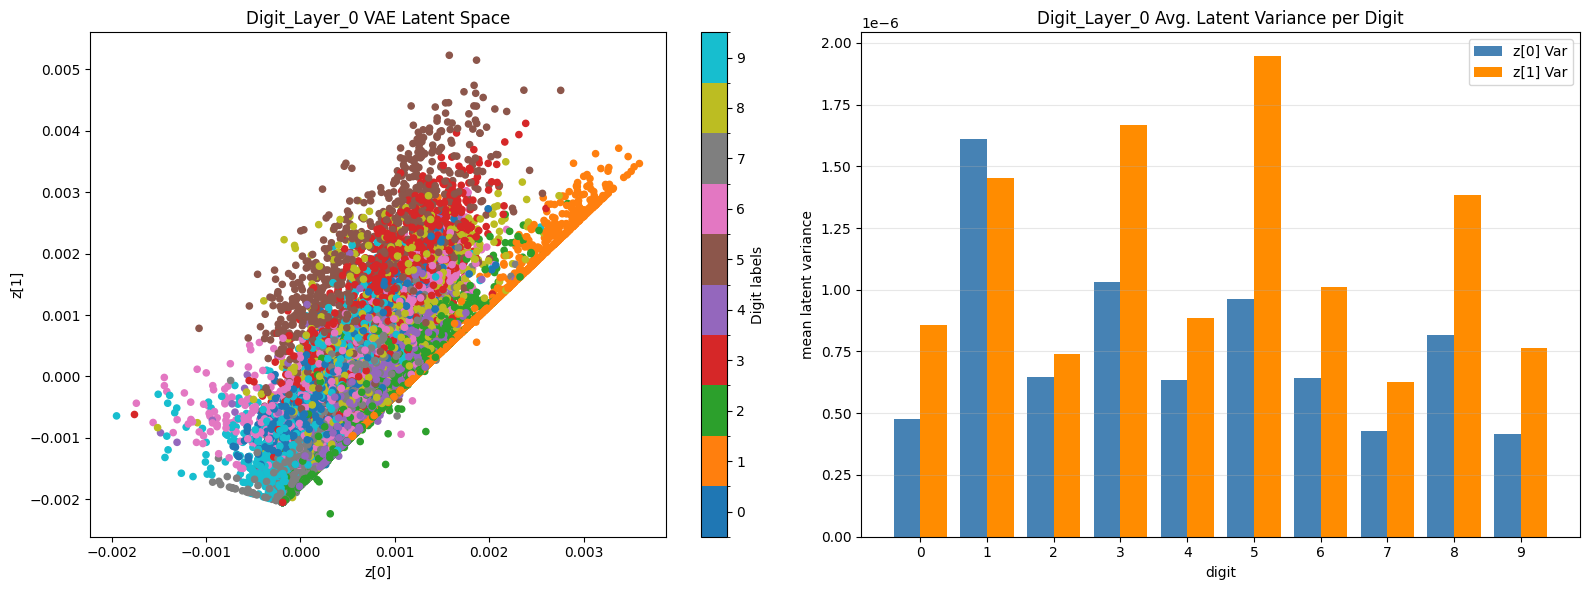

In [179]:
graph_VAE_latent_space(first_layer_vae_model, first_digit_layer_X, "Digit_Layer_0")

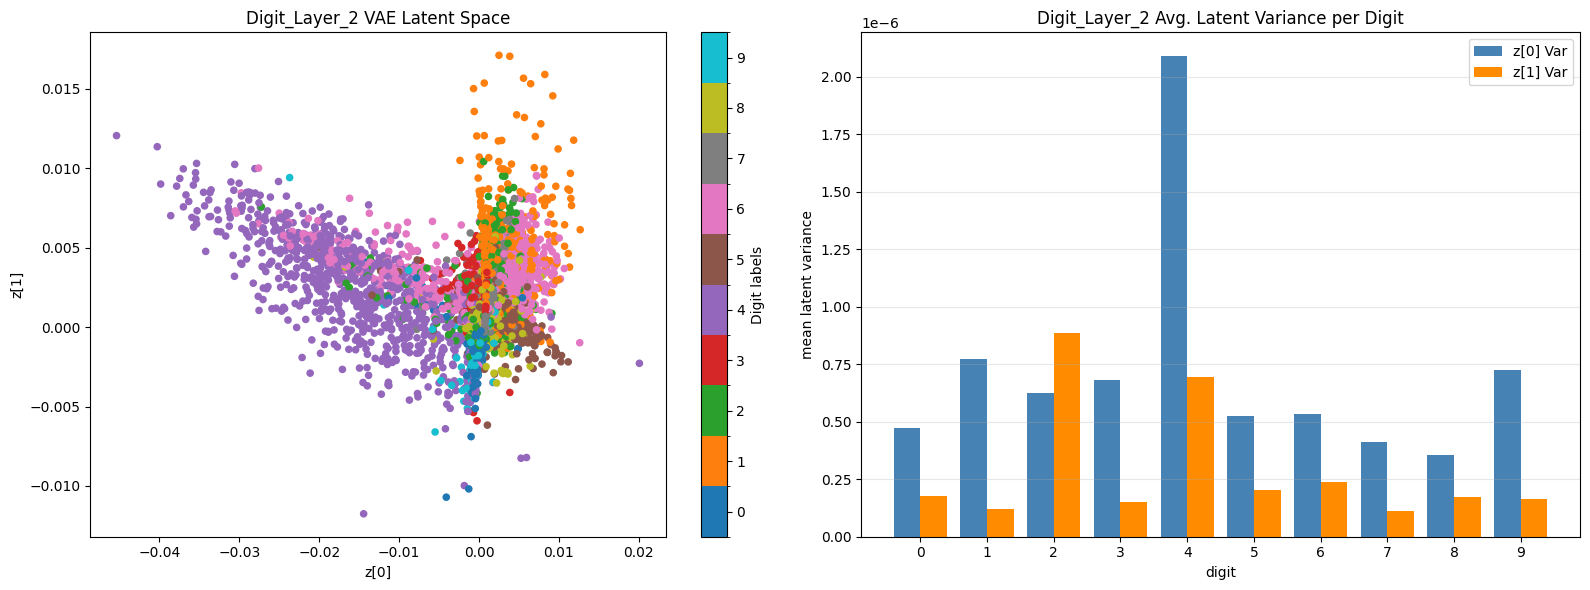

In [187]:
graph_VAE_latent_space(last_layer_vae_model, last_digit_layer_X, "Digit_Layer_2")

In [206]:
def relative_rep(mu, anchors):
    """mu: [B, D], anchors: [K, D] -> [B, K]"""
    mu_n = F.normalize(mu, dim=1)
    a_n = F.normalize(anchors, dim=1)
    return mu_n @ a_n.T   # cosine similarity

def train_VAE_with_relative_align(student_X, likelihood, batch_size, n_epochs, learning_rate,
                                  teacher_model, teacher_X, anchor_indices, rel_lambda=1.0,
                                  latent_dim=2, kl_warmup_epochs=0):
    # Keep track of index labels so that we can sync up a batch from student_X with the same entries in teacher_X
    index_labels = torch.arange(len(student_X))
    loader = DataLoader(TensorDataset(student_X, index_labels), batch_size=batch_size, shuffle=True)
    vae_model = VAE(input_dim=student_X.shape[1], latent_dim=latent_dim,
                    likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

    # Precompute teacher's anchor latents (these anchors do not change)
    with torch.no_grad():
        teacher_mu_anchors, _ = teacher_model.encoder(teacher_X[anchor_indices])

    # Initialize log records
    train_losses = recon_losses = kl_losses = rel_losses = []
    vae_model.train()
    for epoch in range(n_epochs + 1):
        # Reset cumulative loss vars
        tot = rec = kl = rel = 0.0
        kl_w = min(1.0, epoch / kl_warmup_epochs) if kl_warmup_epochs > 0 else 1.0
        for (xb, batch_idx) in loader:
            optimizer.zero_grad()
            recon, student_mu, logvar = vae_model(xb)
            base_loss, recon_loss, kl_loss = vae_loss(recon, xb, student_mu, logvar, likelihood)

            
            # Compute student anchor positions
            student_mu_anchors, _ = vae_model.encoder(student_X[anchor_indices])
            # Computer teacher batch positions
            with torch.no_grad():
                teacher_mu, _ = teacher_model.encoder(teacher_X[batch_idx])
            
            rel_student = relative_rep(student_mu, student_mu_anchors)
            rel_teacher = relative_rep(teacher_mu, teacher_mu_anchors)

            rel_loss = F.mse_loss(rel_student, rel_teacher)
            rel_loss *= rel_lambda
            total = recon_loss + kl_w * kl_loss + rel_loss
            total.backward()
            optimizer.step()

            tot  += total.item()
            rec  += recon_loss.item()
            kl   += kl_loss.item()
            rel  += rel_loss.item()

        train_losses.append(tot); recon_losses.append(rec)
        kl_losses.append(kl); rel_losses.append(rel)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: total={tot:.3f} recon={rec:.3f} "
                  f"kl={kl:.3f} rel={rel:.3f}")

    logs = {"training_losses": train_losses, "recon_losses": recon_losses,
            "kl_losses": kl_losses, "rel_losses": rel_losses}
    return vae_model, logs

In [222]:
# Set training parameters 
n_epochs = 200
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"
teacher_model = first_layer_vae_model
rel_lambda = 25

anchor_indices = np.random.choice(range(last_digit_layer_X.shape[0]), 100)

# Train VAE model
last_layer_vae_model, logs = train_VAE_with_relative_align(last_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate,
                                       teacher_model, first_digit_layer_X, anchor_indices, rel_lambda=rel_lambda, latent_dim=2)

epoch 0: total=1850.661 recon=171.591 kl=58.602 rel=1620.467
epoch 10: total=628.626 recon=169.442 kl=27.265 rel=431.919
epoch 20: total=570.646 recon=168.565 kl=32.494 rel=369.587
epoch 30: total=508.931 recon=169.033 kl=27.298 rel=312.600
epoch 40: total=481.571 recon=168.611 kl=28.331 rel=284.628
epoch 50: total=440.682 recon=168.741 kl=24.038 rel=247.903
epoch 60: total=400.166 recon=169.297 kl=20.490 rel=210.379
epoch 70: total=423.271 recon=169.299 kl=22.946 rel=231.025
epoch 80: total=366.954 recon=169.599 kl=18.140 rel=179.215
epoch 90: total=347.139 recon=169.987 kl=15.825 rel=161.327
epoch 100: total=328.817 recon=169.585 kl=15.106 rel=144.126
epoch 110: total=316.464 recon=169.764 kl=15.248 rel=131.452
epoch 120: total=413.267 recon=169.577 kl=18.388 rel=225.302
epoch 130: total=311.840 recon=169.818 kl=15.652 rel=126.371
epoch 140: total=299.978 recon=169.609 kl=17.149 rel=113.219
epoch 150: total=348.973 recon=169.424 kl=16.265 rel=163.283
epoch 160: total=324.217 recon=16

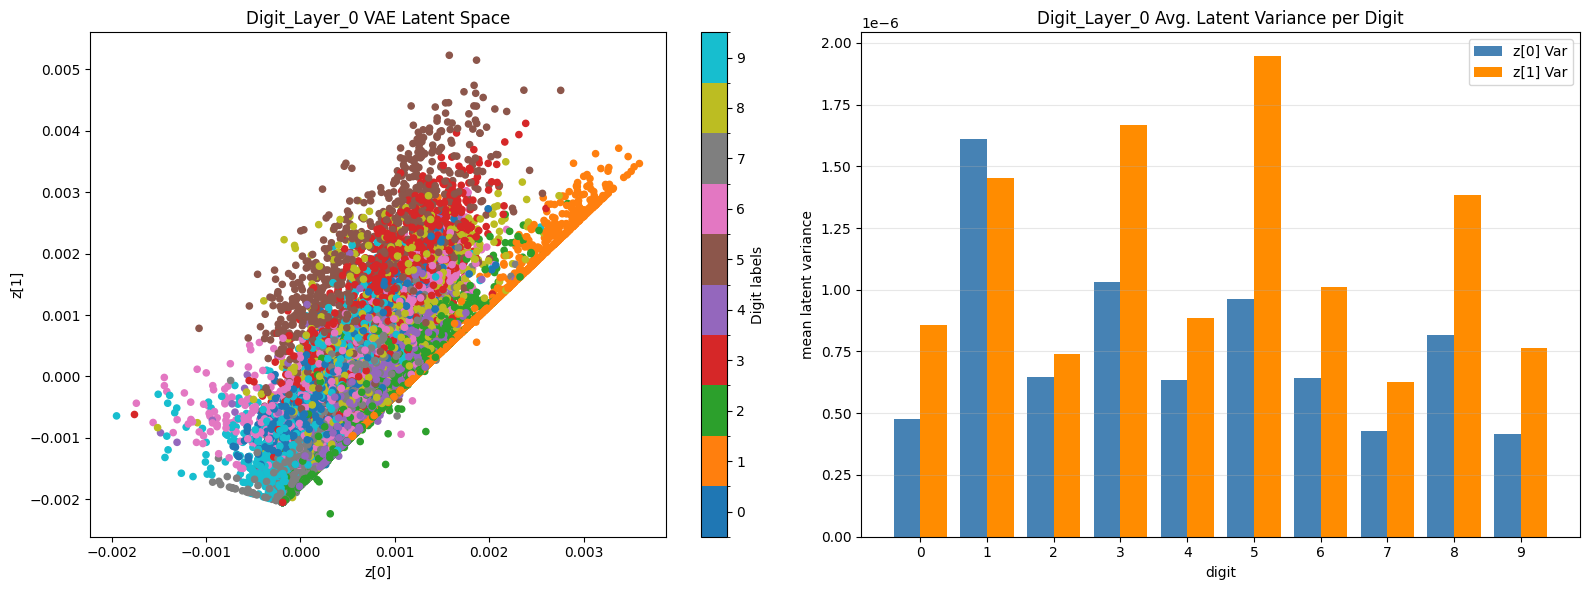

In [213]:
graph_VAE_latent_space(first_layer_vae_model, first_digit_layer_X, "Digit_Layer_0")

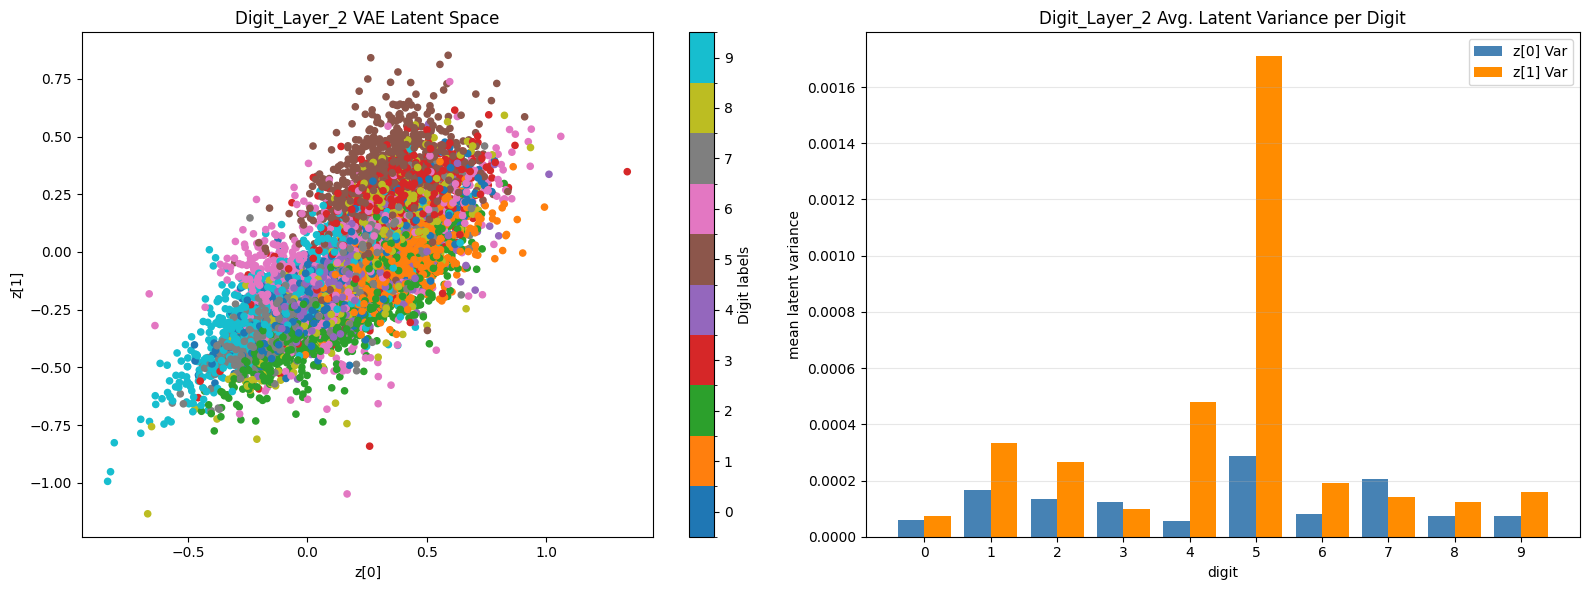

In [223]:
graph_VAE_latent_space(last_layer_vae_model, last_digit_layer_X, "Digit_Layer_2")